# Paper 08: Focal Loss for Dense Object Detection
**Authors**: Tsung-Yi Lin, Priya Goyal, Ross Girshick, Kaiming He, Piotr Dollár (2017)

---

## 1. The Historical Breaking Point: The 100,000:1 Imbalance Crisis
In 2017, one-stage object detectors (YOLO, SSD) were fast, but their accuracy lagged 5–10 mAP behind two-stage detectors (Faster R-CNN).

- **The Root Cause**: Dense detectors sample $\sim 100,000$ candidate anchor locations across an image grid. Only $10-100$ contain actual objects ($0.1\%$), while $>99.9\%$ are trivial background.
- **Failure of Cross-Entropy**: Even if each easy background anchor incurs a small loss (e.g. $-\log(0.99) \approx 0.01$), their massive quantity ($100,000 \times 0.01 = 1000$) completely overwhelms the rare foreground gradients ($10 \times 2.0 = 20$). The model learns to classify blank sky rather than detecting objects!

## 2. The First-Principles Solution: The Modulating Factor
Instead of heuristic negative sampling, reshape the loss function itself:
$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

- When an example is **well-classified** ($p_t \to 1$): $(1 - p_t)^\gamma$ drops to near-zero. With $\gamma=2$, loss for $p_t=0.99$ is suppressed by **$10,000\times$**!
- When an example is **hard and misclassified** ($p_t \to 0$): $(1 - p_t)^\gamma \approx 1$, leaving the loss unaffected.

In this notebook, you will test `BinaryFocalLoss` and `FocalLoss` implemented in `model.py`.

---
## Setup
`%autoreload 2` automatically reloads your code from `model.py` whenever changes are saved.

In [4]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from model import BinaryFocalLoss, FocalLoss
from core.optimizers import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: Loss Equivalence & Modulating Suppression Verification

We verify:
1. When $\gamma=0$ and unweighted, Focal Loss is mathematically identical to standard Cross-Entropy.
2. Easy examples ($p_t \approx 0.99$) are heavily suppressed relative to hard examples ($>10,000\times$ suppression).
3. Multi-class Focal Loss works across both 1D vectors and 2D spatial dense segmentation maps.

In [24]:
print("Testing Gamma=0 matches Standard Cross-Entropy:")
tests.test_gamma_zero_equals_ce(BinaryFocalLoss, FocalLoss)

print("\nTesting Easy Example Down-weighting:")
tests.test_easy_example_downweighting(BinaryFocalLoss)

print("\nTesting Multi-Class and Spatial Shapes:")
tests.test_multiclass_and_spatial_shapes(FocalLoss)

Testing Gamma=0 matches Standard Cross-Entropy:
  [PASS] BinaryFocalLoss(gamma=0) matches standard BCE exactly (diff: 0.00e+00)!
  [PASS] Multi-class FocalLoss(gamma=0) matches standard CE exactly (diff: 0.00e+00)!

Testing Easy Example Down-weighting:
  [PASS] Easy example suppressed by 22026.6x relative to hard example (gamma=2.0)!

Testing Multi-Class and Spatial Shapes:
  [PASS] Multi-class Focal Loss supports both 1D vectors and 2D dense spatial maps!


True

---
## Part 2: Numerical Stability & Extreme Imbalance Gate

We verify:
1. Numerical stability under extreme logits ($-500$ to $+500$) producing zero NaNs or Infs.
2. **Extreme Imbalance Gate**: Training a model under an extreme 99:1 background-to-foreground imbalance ratio.

In [14]:
print("Testing Numerical Stability under Extreme Logits:")
tests.test_numerical_stability(BinaryFocalLoss, FocalLoss)

print("\nTesting 99:1 Extreme Class Imbalance Overfit Gate:")
tests.test_extreme_imbalance_overfit(BinaryFocalLoss)

Testing Numerical Stability under Extreme Logits:
  [PASS] Numerical stability verified: zero NaNs under extreme logit ranges (-500 to +500)!

Testing 99:1 Extreme Class Imbalance Overfit Gate:
  [PASS] 99:1 Extreme Imbalance gate passed: rare target probability reached 73.9%!


True

---
## Part 3: Visualizing Focal Loss (Reproducing Paper Figure 1)

We plot the loss $\text{FL}(p_t) = -(1 - p_t)^\gamma \log(p_t)$ as a function of the probability of ground-truth class $p_t \in [0.001, 1.0]$ for $\gamma \in \{0, 0.5, 1, 2, 5\}$.

Notice how increasing $\gamma$ selectively flattens the curve for well-classified examples ($p_t > 0.5$) while retaining steep gradients for hard examples ($p_t < 0.2$)!

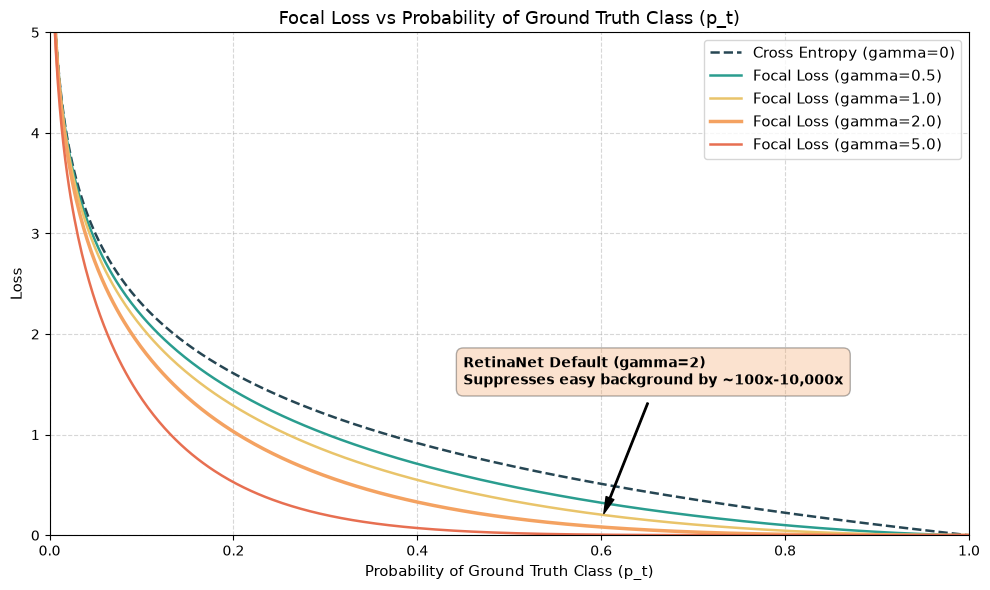

In [13]:
p_t = torch.linspace(0.001, 1.0, 500)
gammas = [0.0, 0.5, 1.0, 2.0, 5.0]
colors = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']

plt.figure(figsize=(10, 6))

for gamma, color in zip(gammas, colors):
    modulating = (1.0 - p_t) ** gamma
    ce = -torch.log(p_t)
    fl = modulating * ce
    
    label = f'Cross Entropy (gamma=0)' if gamma == 0 else f'Focal Loss (gamma={gamma})'
    linewidth = 2.5 if gamma == 2.0 else 1.8
    linestyle = '--' if gamma == 0 else '-'
    plt.plot(p_t.numpy(), fl.numpy(), label=label, color=color, linewidth=linewidth, linestyle=linestyle)

plt.title('Focal Loss vs Probability of Ground Truth Class (p_t)', fontsize=13)
plt.xlabel('Probability of Ground Truth Class (p_t)', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.ylim(0, 5)
plt.xlim(0, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.annotate('RetinaNet Default (gamma=2)\nSuppresses easy background by ~100x-10,000x', 
             xy=(0.6, 0.15), xytext=(0.45, 1.5),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f4a261', alpha=0.3))
plt.tight_layout()
plt.show()